In [1]:
import joblib
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt 
from sklearn.metrics import f1_score
from sklearn.tree import DecisionTreeClassifier

In [2]:
data = joblib.load("../processed_data.joblib")

In [3]:
depth_range = list(range(3,26))
f1_train = []
f1_test = []

In [4]:
for i in depth_range :
    dec_Tree = DecisionTreeClassifier(max_depth= i , random_state=42)
    dec_Tree.fit(data['x_train'] , data['y_train'])
    pred_train = dec_Tree.predict(data['x_train'])
    pred_test = dec_Tree.predict(data['x_test'])
    f1_train.append(f1_score(data['y_train'],pred_train , average='macro'))
    f1_test.append(f1_score(data['y_test'],pred_test, average='macro'))

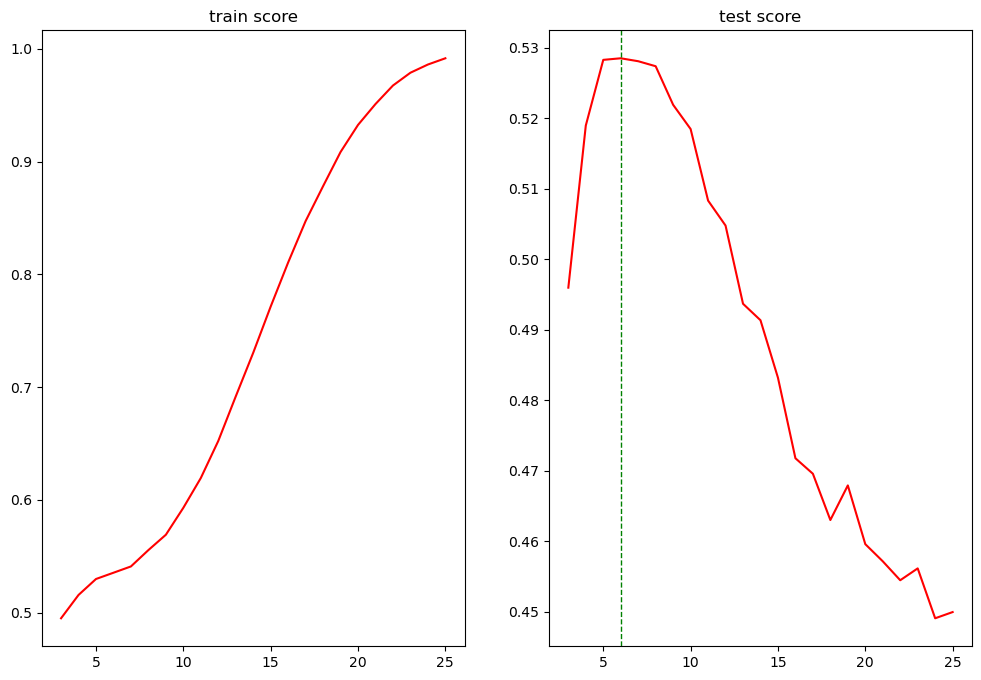

In [5]:
best_depth = depth_range[np.argmax(f1_test)]
fig, ax = plt.subplots(1, 2, figsize=(12, 8))
sns.lineplot(x = depth_range , y = f1_train , c = "red" ,ax= ax[0])
sns.lineplot(x = depth_range , y = f1_test , c = "red" , ax = ax[1])
ax[1].axvline(x = best_depth,  c  ='g' , linestyle = '--' , linewidth = 1 ,   label = 'perfect fit'  )
ax[0].set_title("train score")
ax[1].set_title("test score")
plt.show()